# Teoria da Decisão & Inferência Bayesiana Aplicada: Mega-Sena
### Modelagem Probabilística, Geometria do Acaso e Decisão Ótima sob Incerteza

> **Fundamentação Epistemológica e Teórica:**
> Este estudo constitui um laboratório analítico e computacional que transpõe para o contexto empírico das loterias da Caixa Econômica Federal os fundamentos formais da **Teoria da Decisão Estatística sob Incerteza**, da **Inferência Bayesiana** e da **Combinatória Estocástica**, integrando quatro pilares teóricos da literatura científica:
>
> 1. **Teoria da Decisão e Inferência Bayesiana (Luís Gustavo Esteves, Rafael Izbicki e Rafael Bassi Stern):**
>    A formulação de uma aposta deixa de ser tratada como mero palpite empírico e é rigorosamente formalizada como o problema de decisão sob incerteza $(\mathcal{A}, \Theta, P, U)$. Sob o Teorema da Utilidade Esperada, a escolha racional é guiada pela **Alternativa de Bayes**, que seleciona a ação que maximiza a utilidade esperada a posteriori a partir da atualização de crenças via modelo conjugado Beta-Binomial.
>
> 2. **A Geometria do Acaso e Gabaritos Diofantinos de Cores (Renato Gianella, 2013):**
>    Em *The Geometry of Chance: Lotto Numbers Follow a Predicted Pattern*, Gianella demonstra que, embora todo bilhete individual (micro-estado) possua estritamente a mesma probabilidade $1/\binom{N}{k}$, as partições do espaço amostral em gabaritos de cores geram macro-estados com probabilidades combinatórias drasticamente desiguais. Pela Lei dos Grandes Números de Jacques Bernoulli, os sorteios convergem inevitavelmente para os gabaritos de maior entropia e probabilidade combinatória acumulada.
>
> 3. **Simulação Computacional e Análise Hipergeométrica (Arthur da Costa Almeida e Allan Teixeira Almeida, 2020):**
>    Em *Simulação Computacional: um estudo de caso com as loterias federais*, demonstra-se via experimentos de Monte Carlo e distribuição analítica hipergeométrica exata que o retorno financeiro esperado de qualquer aposta é estritamente negativo ($\mathbb{E}[\text{Retorno}] < 0$). As loterias institucionais retêm cerca de 56% da arrecadação para repasses sociais e despesas, devolvendo apenas cerca de 44% em prêmios. A modelagem científica serve, portanto, à racionalidade probabilística e à desmistificação de esquemas ilusórios.
>
> 4. **Aprendizado Supervisionado e Algoritmos Evolutivos (Fernando Barbosa et al., 2013; Thiago Zanin; Rafael Izbicki & Tiago Mendonça dos Santos, 2020):**
>    Estruturação do problema preditivo via classificação multirrótulo com regularização $L_2$, janelas móveis multitemporais e rigor metodológico absoluto de *Zero Lookahead Bias* (ausência total de vazamento temporal).

---

## Dinâmica do Jogo e Métricas Operacionais
Na modalidade **Mega-Sena**, o volante é composto por **60 dezenas**, das quais exatamente **6 dezenas** são sorteadas por concurso.
- Espaço amostral total: $\binom{60}{6}$ combinações simples equiprováveis.
- Probabilidade teórica neutra de cada dezena individual:
  $$\mathbb{E}[\theta_i] = \frac{6}{60} = 0.10 = 0.1000 (10.0%)$$
- Priori neutra justa: $\text{Beta}(1.0, 9.0)$ com hiperparâmetros $\alpha_0 = 1.0$ e $\beta_0 = 9.0$.
- Partição de Gianella: 6 cores com 10 dezenas cada (01-10, 11-20, 21-30, 31-40, 41-50, 51-60).


In [1]:
import sys
import os

# Garante a localização do módulo mega_sena_models a partir da raiz ou da pasta notebooks/
for path_cand in ['.', '..', os.path.dirname(os.getcwd())]:
    if os.path.exists(os.path.join(path_cand, 'mega_sena_models.py')):
        if path_cand not in sys.path:
            sys.path.insert(0, path_cand)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from scipy.stats import beta

from mega_sena_models import (
    load_lottery_data,
    find_latest_lottery_file,
    FrequencyDelayModel,
    MultiLabelMLModel,
    BayesianDecisionModel,
    GianellaColorTemplateModel,
    GianellaBayesHybridModel,
    BayesianHybridModel,
    LotteryBaggingModel,
    LotteryPastingModel,
    LotteryAdaBoostModel,
    LotteryGradientBoostingModel,
    LotteryStochasticGradientBoostingModel,
    LotteryLogitGradientBoostingModel,
    LotteryResidualCyclingGradientBoostingModel,
    LotteryStackingModel,
    LotteryMomentumEnsembleModel,
    LotteryBalancedEnsembleModel,
    predict_momentum_ensemble,
    predict_balanced_ensemble,
    predict_bagging,
    predict_pasting,
    predict_adaboost,
    predict_gradient_boosting,
    predict_stochastic_gradient_boosting,
    predict_logit_gradient_boosting,
    predict_residual_cycling_gradient_boosting,
    predict_stacking,
    run_all_lottery_methods
)

# Configuração estética dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# Carregando base histórica
EXCEL_PATH = find_latest_lottery_file('megasena')
df, binary_matrix, cfg = load_lottery_data(EXCEL_PATH, game='megasena')
n_sorteios, n_dezenas = binary_matrix.shape
next_concurso = int(df['Concurso'].max()) + 1

print(f"Modalidade: {cfg['name']} | Concursos Históricos Carregados: {n_sorteios}")
print(f"Total de Dezenas: {cfg['n_dezenas']} | Dezenas Sorteadas por Concurso (k): {cfg['k']}")
print(f"Próximo Concurso Estimado: {next_concurso}")


Modalidade: Mega-Sena | Concursos Históricos Carregados: 3081
Total de Dezenas: 60 | Dezenas Sorteadas por Concurso (k): 6
Próximo Concurso Estimado: 3082


---
## Método 1: Abordagem Estatística (Frequência Ponderada & Atraso Relativo)

### Fundamentação Teórica e Intuição Heurística
Este método equilibra duas forças estatísticas comumente observadas em séries temporais empíricas:

1. **Frequência Ponderada no Tempo ($f_{w, i}$):**
   Aplica decaimento exponencial temporal com meia-vida de 100 concursos:
   $$w_t = 2^{-(T - t) / 100}$$
   Isso atribui peso progressivamente maior aos concursos recentes, captando eventuais micro-tendências ou assimetrias transitórias.

2. **Métrica de Atraso Relativo ($R_i$):**
   Calcula a razão entre o atraso corrente $d_i$ (número de concursos consecutivos em que a dezena $i$ não é sorteada) e seu intervalo médio histórico de espera $\mu_{\text{gap}, i}$:
   $$R_i = \frac{d_i}{\mu_{\text{gap}, i}}$$
   Quando $R_i > 1$, a dezena está demorando mais para sair do que seu padrão histórico médio.

3. **Escore Padronizado Balanceado:**
   Aplica normalização Z-Score para unificar as escalas:
   $$S_i = 0.5 \cdot Z(f_{w, i}) + 0.5 \cdot Z(R_i)$$

Gera 3 perfis de decisão para análise comparativa:
- **Balanceado:** Combina momento recente com pressão de atraso.
- **Mais Atrasadas:** Foco em dezenas com maior déficit empírico.
- **Mais Frequentes Recentes:** Foco no momento atual (*momentum* temporal).


Top 6 Método 1 (Balanceado): [6, 11, 27, 46, 48, 53]
Top 6 Método 1 (Mais Atrasadas): [21, 24, 26, 37, 46, 56]
Top 6 Método 1 (Mais Frequentes Recentes): [6, 17, 27, 40, 43, 58]


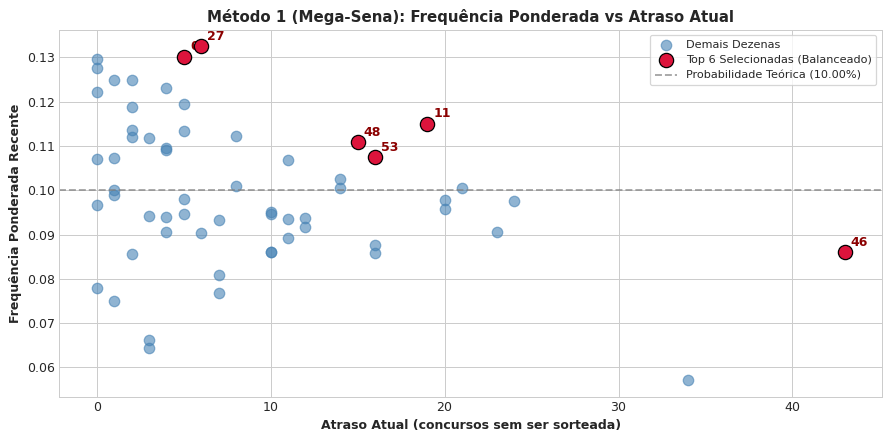

In [2]:
# Treinando o Método 1
m1 = FrequencyDelayModel(half_life=100.0, alpha=0.5)
m1.fit(binary_matrix)
df_m1 = m1.get_scores_df()

pred_m1_bal = m1.predict_top_k(6, strategy='balanced')
pred_m1_over = m1.predict_top_k(6, strategy='overdue')
pred_m1_mom = m1.predict_top_k(6, strategy='momentum')

print(f"Top 6 Método 1 (Balanceado): {pred_m1_bal}")
print(f"Top 6 Método 1 (Mais Atrasadas): {pred_m1_over}")
print(f"Top 6 Método 1 (Mais Frequentes Recentes): {pred_m1_mom}")

# Visualização: Atraso Atual vs Frequência Ponderada
fig, ax = plt.subplots(figsize=(10, 5), dpi=90)
selected_mask = df_m1['dezena'].isin(pred_m1_bal)

ax.scatter(df_m1.loc[~selected_mask, 'atraso_atual'], 
           df_m1.loc[~selected_mask, 'freq_ponderada'],
           c='steelblue', alpha=0.6, s=70, label='Demais Dezenas')

ax.scatter(df_m1.loc[selected_mask, 'atraso_atual'], 
           df_m1.loc[selected_mask, 'freq_ponderada'],
           c='crimson', edgecolors='black', s=130, zorder=5, label=f'Top 6 Selecionadas (Balanceado)')

for _, r in df_m1[selected_mask].iterrows():
    ax.annotate(f"{int(r['dezena']):02d}", 
                (r['atraso_atual'], r['freq_ponderada']),
                textcoords="offset points", xytext=(5, 5), fontweight='bold', color='darkred')

p_ref = 6 / 60
ax.set_title(f"Método 1 (Mega-Sena): Frequência Ponderada vs Atraso Atual", fontsize=12, fontweight='bold')
ax.set_xlabel("Atraso Atual (concursos sem ser sorteada)", fontsize=10, fontweight='bold')
ax.set_ylabel("Frequência Ponderada Recente", fontsize=10, fontweight='bold')
ax.axhline(p_ref, color='gray', linestyle='--', alpha=0.7, label=f'Probabilidade Teórica ({p_ref*100:.2f}%)')
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.show()


---
## Método 2: Machine Learning Supervisionado Multi-label

### Engenharia de Atributos e Aprendizado com Validação Temporal
Neste método, o desafio de prever as dezenas é modelado como um problema de classificação supervisionada multi-rótulo:

1. **Estratégia *Binary Relevance*:**
   Treinam-se 60 modelos independentes (um para cada dezena $i \in \{1, \dots, 60\}$). Cada modelo aprende a função de probabilidade:
   $$P\left(Y_i^{(t+1)} = 1 \mid \mathbf{x}_i^{(t)}\right)$$

2. **Engenharia de Atributos Sem Vazamento de Dados (*Zero Lookahead Bias*):**
   O vetor de características $\mathbf{x}_i^{(t)}$ para o concurso $t+1$ utiliza **estritamente** os dados acumulados até o concurso $t$:
   - **Atraso corrente:** Número de sorteios consecutivos sem sair até o momento $t$.
   - **Frequências móveis multiescala:** Taxa de aparição nas últimas $W$ rodadas ($W \in \{5, 10, 25, 50, 100\}$ concursos).
   - **Defasagens temporais (*Lags*):** Indicadores binários de saída nos concursos $t$, $t-1$ e $t-2$.
   - **Variável de contexto:** Contagem de dezenas pares sorteadas no concurso anterior.

3. **Modelo e Calibração:**
   Utiliza-se Regressão Logística com regularização $L_2$ ($C=0.1$) para evitar sobreajuste (*overfitting*). As probabilidades brutas estimadas são calibradas e normalizadas para que sua soma corresponda exatamente a 6 dezenas (o número de bolas sorteadas). As 6 dezenas com maiores probabilidades calibradas compõem a aposta.


Top 6 Método 2 (Machine Learning Multi-label): [10, 32, 34, 41, 43, 53]


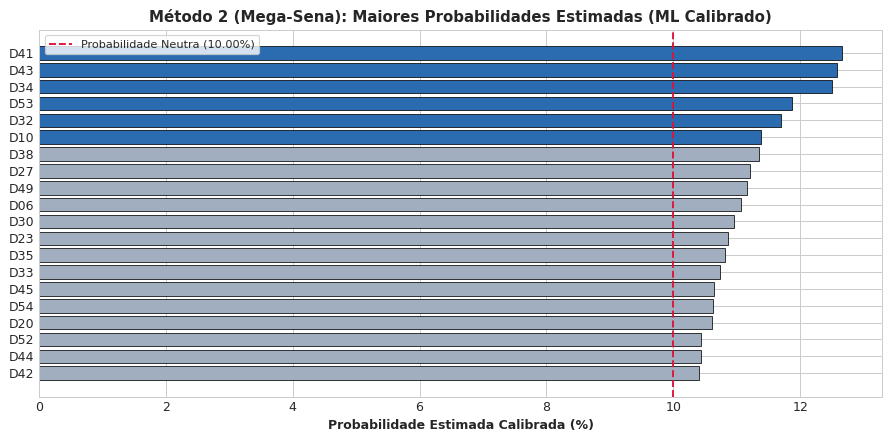

In [3]:
# Treinando o Método 2
m2 = MultiLabelMLModel(estimator='logistic_regression', random_state=42)
m2.fit(binary_matrix)
df_m2 = m2.get_probabilities_df()

pred_m2 = m2.predict_top_k(6)
print(f"Top 6 Método 2 (Machine Learning Multi-label): {pred_m2}")

# Visualização das probabilidades calibradas
fig, ax = plt.subplots(figsize=(10, 5), dpi=90)
top_plot_k = min(20, 60)
df_m2_top = df_m2.head(top_plot_k).sort_values('probabilidade_calibrada_sorteio', ascending=True)

bar_colors = ['#2B6CB0' if d in pred_m2 else '#A0AEC0' for d in df_m2_top['dezena']]
bars = ax.barh([f"D{int(d):02d}" for d in df_m2_top['dezena']], 
               df_m2_top['probabilidade_calibrada_sorteio'] * 100, 
               color=bar_colors, edgecolor='black', linewidth=0.6)

p_ref = (6 / 60) * 100
ax.axvline(p_ref, color='crimson', linestyle='--', linewidth=1.5, label=f'Probabilidade Neutra ({p_ref:.2f}%)')
ax.set_title(f"Método 2 (Mega-Sena): Maiores Probabilidades Estimadas (ML Calibrado)", fontsize=12, fontweight='bold')
ax.set_xlabel("Probabilidade Estimada Calibrada (%)", fontsize=10, fontweight='bold')
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.show()


---
## Método 3: Inferência Bayesiana & Teoria da Decisão

### 1. Formalização do Problema de Decisão $(\mathcal{A}, \Theta, P, U)$
Seguindo os princípios formais da Teoria da Decisão Estatística apresentados por **Esteves, Izbicki e Stern (Capítulo 6)**, estruturamos a aposta da seguinte forma:

* **Espaço de Ações (Decisões) $\mathcal{A}$:** O conjunto de todas as combinações possíveis de apostas $a = \{d_1, \dots, d_6\}$ com $d_j \in \{1, \dots, 60\}$.
* **Espaço de Estados da Natureza $\Theta$:** O resultado real do sorteio $s = \{s_1, \dots, s_6\}$.
* **Medida de Incerteza $P$:** Representada pela distribuição preditiva a posteriori $p(\theta \mid \mathcal{D})$, atualizada a partir do histórico observacional.
* **Função de Utilidade $U(a, s)$:** Recompensa o apostador pelo número de dezenas acertadas:
  $$U(a, s) = |a \cap s| = \sum_{i \in a} \mathbb{I}(i \in s)$$
* **Regra de Decisão de Bayes (Utilidade Esperada):**
  A **Alternativa de Bayes** $a^*$ é a ação que maximiza a utilidade esperada a posteriori:
  $$a^* = \arg\max_{a \in \mathcal{A}} \mathbb{E}[U(a, s) \mid \mathcal{D}] = \arg\max_{a \in \mathcal{A}} \sum_{i \in a} \mathbb{E}[\theta_i \mid \mathcal{D}]$$
  Portanto, a decisão ótima consiste em selecionar as **6 dezenas com as maiores esperanças a posteriori**.

---

### 2. O Modelo Conjugado Beta-Binomial
Para cada dezena $i$, consideramos o sorteio como um processo Bernoulli com taxa desconhecida $\theta_i \in [0, 1]$.

* **Priori Racional Justa:**
  Adota-se uma distribuição a priori $\theta_i \sim \text{Beta}(1.0, 9.0)$, cuja esperança neutra reflete exatamente a probabilidade matemática do jogo:
  $$\mathbb{E}[\theta_i] = \frac{\alpha_0}{\alpha_0 + \beta_0} = \frac{6}{60} = 0.10 = 0.1000 (10.0%)$$
* **Verossimilhança:** $X_i \mid \theta_i \sim \text{Binomial}(n, \theta_i)$.
* **Posteriori Exata:** Pela propriedade de conjugação:
  $$\theta_i \mid X_i = x_i \sim \text{Beta}(\alpha_0 + x_i, \; \beta_0 + n - x_i)$$
* **Esperança a Posteriori e Intervalo de Credibilidade (95%):**
  $$\mathbb{E}[\theta_i \mid x_i] = \frac{\alpha_0 + x_i}{\alpha_0 + \beta_0 + n}$$

---

### 3. As Duas Abordagens Bayesianas: Global vs. Adaptativo
Calculamos e comparamos duas formulações da decisão bayesiana:
* **Conjugado Global (Histórico Total):** Considera todos os concursos de forma cumulativa com pesos iguais. É altamente estável e mede a tendência estrutural de longo prazo, com intervalos de credibilidade muito estreitos.
* **Dinâmico Adaptativo (Ponderado no Tempo):** Aplica fator de decaimento exponencial (meia-vida de 150 concursos) nas contagens pseudo-amostrais, focando no regime físico recente dos sorteios.


Top 6 Decisão Ótima de Bayes (Conjugado Global): [5, 10, 27, 33, 37, 53]
Top 6 Decisão Ótima de Bayes (Dinâmico Adaptativo): [6, 10, 14, 17, 27, 43]


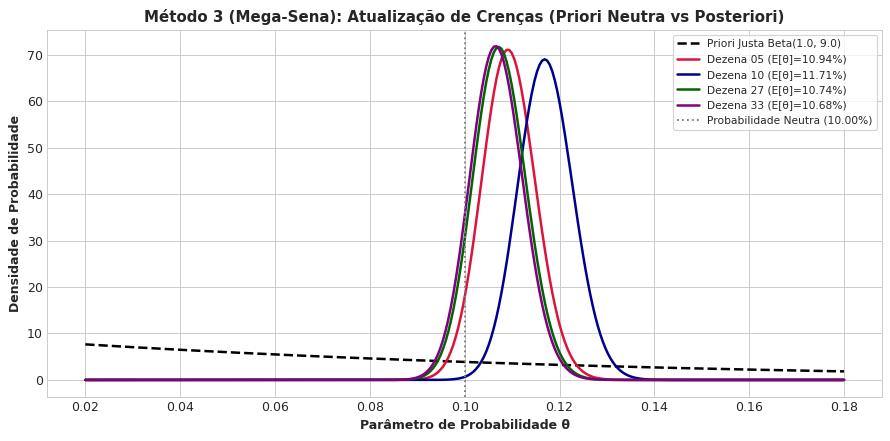

In [4]:
# 3a. Modelo Bayesiano Conjugado Global
m3_static = BayesianDecisionModel(alpha_0=1.0, beta_0=9.0)
m3_static.fit(binary_matrix)
df_m3 = m3_static.get_posterior_df()

pred_m3_static = m3_static.predict_top_k(6)
print(f"Top 6 Decisão Ótima de Bayes (Conjugado Global): {pred_m3_static}")

# 3b. Modelo Bayesiano Dinâmico Adaptativo
m3_dyn = BayesianDecisionModel(alpha_0=1.0, beta_0=9.0, decay_half_life=150.0)
m3_dyn.fit(binary_matrix)
df_m3_dyn = m3_dyn.get_posterior_df()

pred_m3_dyn = m3_dyn.predict_top_k(6)
print(f"Top 6 Decisão Ótima de Bayes (Dinâmico Adaptativo): {pred_m3_dyn}")

# Visualização da Densidade a Posteriori vs Priori
fig, ax = plt.subplots(figsize=(10, 5), dpi=90)
theta_vals = np.linspace(max(0, 6/60 - 0.08), min(1, 6/60 + 0.08), 300)

# Priori Neutra
prior_pdf = beta.pdf(theta_vals, 1.0, 9.0)
ax.plot(theta_vals, prior_pdf, 'k--', linewidth=2, label='Priori Justa Beta(1.0, 9.0)')

# Posteriori das top dezenas
sample_dezenas = pred_m3_static[:min(4, len(pred_m3_static))]
colors_top = ['crimson', 'darkblue', 'darkgreen', 'purple']
for d, c in zip(sample_dezenas, colors_top):
    row = df_m3[df_m3['dezena'] == d].iloc[0]
    post_pdf = beta.pdf(theta_vals, row['post_alpha'], row['post_beta'])
    ax.plot(theta_vals, post_pdf, color=c, linewidth=2, label=f"Dezena {int(d):02d} (E[θ]={row['esperanca_posteriori']*100:.2f}%)")

p_ref = 6 / 60
ax.axvline(p_ref, color='gray', linestyle=':', label=f'Probabilidade Neutra ({p_ref*100:.2f}%)')
ax.set_title(f"Método 3 (Mega-Sena): Atualização de Crenças (Priori Neutra vs Posteriori)", fontsize=12, fontweight='bold')
ax.set_xlabel("Parâmetro de Probabilidade θ", fontsize=10, fontweight='bold')
ax.set_ylabel("Densidade de Probabilidade", fontsize=10, fontweight='bold')
ax.legend(frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()


---
## Método 4: A Geometria do Acaso (Gabaritos Diofantinos de Cores — Renato Gianella, 2013)

### Fundamentação Teórica e Formulação Matemática
Em sua obra seminal *The Geometry of Chance: Lotto Numbers Follow a Predicted Pattern* (Revista Brasileira de Biometria, 2013), o matemático e pesquisador **Renato Gianella** introduz uma abordagem analítica que concilia a teoria combinatória com a Lei dos Grandes Números:

1. **Partição em Grupos de Cores:**
   O conjunto universal de dezenas $S_{60}$ é particionado em $C = 6$ grupos disjuntos e regulares de tamanho $g = 10$, cada qual associado a uma cor $c_i$:
   $$(D_0, D_1, \dots, D_{5})$$
   Na **Mega-Sena**, temos 6 cores com 10 dezenas cada (01-10, 11-20, 21-30, 31-40, 41-50, 51-60).

2. **A Equação Diofantina Linear:**
   Seja $x_i$ a quantidade de dezenas sorteadas pertencentes ao grupo de cor $i$ ($0 \le x_i \le 10$). Como são sorteadas exatamente $6$ dezenas em cada concurso, a soma das dezenas por cor satisfaz a equação diofantina linear:
   $$\sum_{i=0}^{5} x_i = 6, \quad \text{com } x_i \in \mathbb{N}_{\ge 0}$$

3. **Gabaritos Diofantinos de Cores (Templates):**
   Um gabarito de cores $T$ é uma partição inteira decrescente de $6$ em até $6$ partes:
   $$T = (x_{(1)}, x_{(2)}, \dots, x_{(6)}), \quad \text{onde } x_{(1)} \ge x_{(2)} \ge \dots \ge x_{(6)}$$
   O número total de combinações simples associadas a esse gabarito é dado pelo produto combinatório hipergeométrico multivariado e pela permutação das cores com repetição:
   $$\text{Comb}(T) = \frac{6!}{\prod_{j} m_j!} \cdot \prod_{i=0}^{5} \binom{10}{x_i}$$
   onde $m_j$ é a multiplicidade de cada valor de contagem no gabarito. A probabilidade combinatória teórica de cada macro-estado é:
   $$P(T) = \frac{\text{Comb}(T)}{\binom{60}{6}}$$

4. **Princípio da Invariância do Micro-Estado vs Dispersão do Macro-Estado:**
   - **Micro-Estado:** Qualquer bilhete individual tem rigorosamente a mesma probabilidade $1/\binom{60}{6}$ de ser sorteado em um concurso.
   - **Macro-Estado:** Os gabaritos diofantinos agrupam volumes extremamente desiguais de combinações simples. Gabaritos de alta entropia (dispersão equilibrada entre as cores) concentram de 70% a 90% de todo o espaço amostral, enquanto gabaritos monocromáticos ou fortemente concentrados detêm frações desprezíveis ($< 0.05%$).

5. **A Lei dos Grandes Números e a Regra de Decisão de Gianella:**
   Pela Lei dos Grandes Números de Jacques Bernoulli, as frequências relativas empíricas observadas ao longo da história dos sorteios convergem com precisão matemática para as probabilidades combinatórias teóricas $P(T)$.
   A regra de decisão racional de Gianella preconiza que o apostador deve selecionar bilhetes que **pertençam estritamente ao gabarito mais provável** (macro-estado de maior probabilidade combinatória), preenchendo as cotas das cores mais ativas com as dezenas de maior atratividade empírica e bayesiana.


Top 6 Método 4 (Gianella - Gabarito Diofantino): [5, 10, 37, 38, 43, 53]
Gabarito Teórico Mais Provável: (2, 2, 1, 1, 0, 0)

Principais Gabaritos Diofantinos de Cores (Teórico vs Empírico):
   template  combinacoes  freq_teorica_pct  ocorrencias  freq_empirica_pct   dif_pct
2-2-1-1-0-0     18225000         36.403505         1108          35.962350 -0.441156
2-1-1-1-1-0     13500000         26.965560          846          27.458617  0.493058
3-1-1-1-0-0      7200000         14.381632          478          15.514443  1.132812
3-2-1-0-0-0      6480000         12.943469          377          12.236287 -0.707182
2-2-2-0-0-0      1822500          3.640351          109           3.537812 -0.102538
4-1-1-0-0-0      1260000          2.516786           71           2.304447 -0.212339


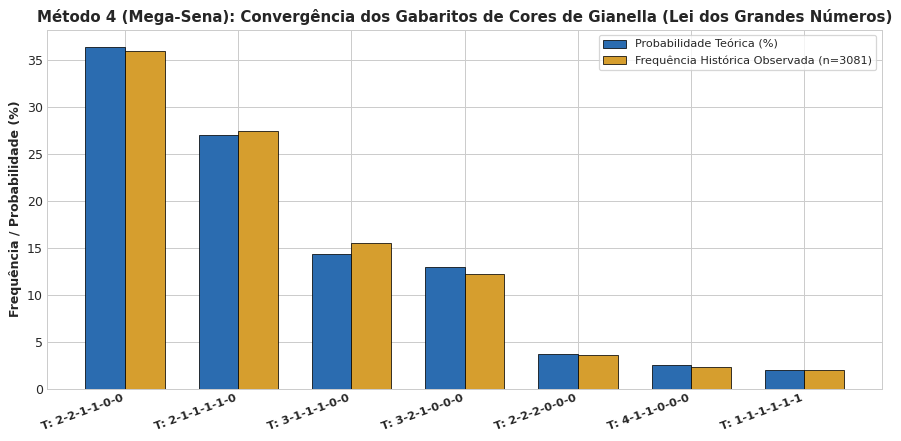

In [5]:
# Treinando o Método 4: A Geometria do Acaso (Gianella)
m4 = GianellaColorTemplateModel(n_dezenas=60, k=6, group_size=10)
m4.fit(binary_matrix)
df_templates = m4.get_template_stats_df()

pred_m4 = m4.predict_top_k(6)
print(f"Top 6 Método 4 (Gianella - Gabarito Diofantino): {pred_m4}")
print(f"Gabarito Teórico Mais Provável: {m4.top_template_}")

# Exibição dos principais gabaritos
print("\nPrincipais Gabaritos Diofantinos de Cores (Teórico vs Empírico):")
display_cols = ['template', 'combinacoes', 'freq_teorica_pct', 'ocorrencias', 'freq_empirica_pct', 'dif_pct']
print(df_templates[display_cols].head(6).to_string(index=False))

# Gráfico Comparativo: Probabilidade Teórica vs Frequência Empírica (Lei dos Grandes Números)
fig, ax = plt.subplots(figsize=(10, 5), dpi=90)
top_plot_templates = df_templates.head(min(7, len(df_templates)))
x_pos = np.arange(len(top_plot_templates))
bar_w = 0.35

ax.bar(x_pos - bar_w/2, top_plot_templates['freq_teorica_pct'], width=bar_w, 
       label='Probabilidade Teórica (%)', color='#2B6CB0', edgecolor='black', linewidth=0.6)
ax.bar(x_pos + bar_w/2, top_plot_templates['freq_empirica_pct'], width=bar_w, 
       label=f'Frequência Histórica Observada (n={n_sorteios})', color='#D69E2E', edgecolor='black', linewidth=0.6)

ax.set_xticks(x_pos)
ax.set_xticklabels([f"T: {t}" for t in top_plot_templates['template']], rotation=20, ha='right', fontsize=9, fontweight='bold')
ax.set_title(f"Método 4 (Mega-Sena): Convergência dos Gabaritos de Cores de Gianella (Lei dos Grandes Números)", fontsize=12, fontweight='bold')
ax.set_ylabel("Frequência / Probabilidade (%)", fontsize=10, fontweight='bold')
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.show()


---
## Comparação Consolidada dos 4 Métodos Analíticos
Abaixo sintetizamos as 6 dezenas recomendadas por cada uma das **7 abordagens analíticas e subestratégias** implementadas:
1. **Método 1 (Estatístico - Balanceado):** Z-Score ponderado entre frequência exponencial e atraso relativo.
2. **Método 1 (Mais Atrasadas):** Foco puro em déficit empírico e gap temporal.
3. **Método 1 (Mais Frequentes Recentes):** Foco em aceleração e momento recente (*momentum*).
4. **Método 2 (Machine Learning Multi-label Calibrado):** Regressão logística com *Zero Lookahead Bias* e calibração estocástica.
5. **Método 3 (Bayesiano Conjugado Global):** Modelo Beta-Binomial sobre o histórico total com priori racional neutra.
6. **Método 3 (Bayesiano Dinâmico Adaptativo):** Modelo Beta-Binomial com evidência ponderada no tempo (regime mecânico recente).
7. **Método 4 (Gianella - Geometria do Acaso):** Aposta condicionada ao gabarito diofantino ótimo de cores de maior probabilidade combinatória.

Identificamos a **análise de consenso** (dezenas com convergência de múltiplos modelos independentes) para estruturar a decisão final.


In [6]:
# Execução de todos os métodos analíticos de forma consolidada
results = run_all_lottery_methods(EXCEL_PATH, game='megasena', next_concurso=next_concurso, include_hybrids=True)
comp_df = results['comparison_df']

print("=" * 85)
print(f"QUADRO COMPARATIVO OFICIAL DE ESTIMATIVAS — MEGA-SENA (CONCURSO {next_concurso})")
print("=" * 85)
for _, r in comp_df.iterrows():
    print(f"• {r['Metodo']:<50} -> [{r['Dezenas Previstas']}]")
print("=" * 85)

# Apuração de Consenso entre os 7 Modelos
vote_counts = {}
for name_m, nums in results['predictions'].items():
    for d in nums:
        vote_counts[d] = vote_counts.get(d, 0) + 1

post_df_ref = results['m3_static'].get_posterior_df().set_index('dezena')
sorted_consensus = sorted(vote_counts.items(), 
                          key=lambda x: (x[1], post_df_ref.loc[x[0], 'esperanca_posteriori']), 
                          reverse=True)
bet_consenso = sorted([x[0] for x in sorted_consensus[:6]])

print(f"★ DECISÃO ÓTIMA DE BAYES (Consenso Multi-modelo): {bet_consenso}")


QUADRO COMPARATIVO OFICIAL DE ESTIMATIVAS — MEGA-SENA (CONCURSO 3082)
• Metodo 1 (Estatistico - Balanceado)                -> [06, 11, 27, 46, 48, 53]
• Metodo 1 (Sub-estrategia Mais Atrasadas)           -> [21, 24, 26, 37, 46, 56]
• Metodo 1 (Sub-estrategia Mais Frequentes Recentes) -> [06, 17, 27, 40, 43, 58]
• Metodo 2 (Machine Learning Multi-label Calibrado)  -> [10, 32, 34, 41, 43, 53]
• Metodo 3 (Bayesiano Conjugado Global)              -> [05, 10, 27, 33, 37, 53]
• Metodo 3 (Bayesiano Dinamico Adaptativo)           -> [06, 10, 14, 17, 27, 43]
• Metodo 4 (Gianella - Geometria do Acaso)           -> [05, 10, 37, 38, 43, 53]
• Decisao Otima de Bayes (Consenso)                  -> [05, 10, 27, 37, 43, 53]
• Metodo 5 (Gianella + Bayes Global)                 -> [05, 10, 37, 38, 43, 53]
• Metodo 6 (Gianella + Bayes Adaptativo)             -> [06, 10, 17, 38, 40, 43]
• Metodo 7 (Gianella + Melhor Decisao de Bayes)      -> [05, 10, 33, 37, 43, 53]
• Metodo 8 (Gianella + Regressao Logist

---
## Considerações Críticas, Ética e Limitações Metodológicas

### 1. Retorno Esperado Estritamente Negativo e a Falácia do Apostador
Como demonstram **Arthur da Costa Almeida e Allan Teixeira Almeida (2020)** em seu estudo computacional sobre as loterias federais:
* **Estrutura de Repasse:** A arrecadação bruta das loterias da Caixa é repartida por lei: cerca de **56% a 57%** é compulsoriamente destinada a repasses sociais (seguridade social, segurança pública, educação, esporte e cultura) e custos operacionais, retornando apenas **43.35% a 45%** aos apostadores como premiação bruta.
* **Esperança Matemática:** Consequentemente, para qualquer combinação e qualquer modalidade, o retorno financeiro esperado é estritamente negativo:
  $$\mathbb{E}[\text{Retorno Financeiro}] < 0 \quad (\approx -55\%)$$
* **Equiprobabilidade dos Micro-Estados:** Nenhuma técnica de inteligência artificial, inferência bayesiana ou análise combinatória é capaz de alterar a probabilidade *ex ante* de um bilhete individual em um jogo justo:
  $$P(\text{combinação}) = \frac{1}{\binom{60}{6}}$$
  Qualquer crença em "números que devem sair" incorre na **Falácia do Apostador (*Gambler's Fallacy*)**.

### 2. O Papel Científico da Teoria da Decisão
Como ensinam os professores **Luís Gustavo Esteves, Rafael Izbicki e Rafael Bassi Stern**, a modelagem formal de decisões sob incerteza **não visa prometer riqueza nem adivinhar o futuro**. Seu valor científico reside em:
- **Racionalidade Axiomática:** Substituir palpites aleatórios por uma formulação coerente de preferências e maximização de utilidade esperada.
- **Transparência Epistêmica:** O método bayesiano explicita quantitativamente a incerteza residual por meio de Intervalos de Credibilidade a 95%, impedindo falsas promessas determinísticas.
- **Consenso Estruturado:** A combinação entre modelos de longo prazo (estáticos), regimes dinâmicos (adaptativos), aprendizado de máquina e gabaritos diofantinos (Gianella) oferece o mais alto grau de consistência matemática possível diante dos dados empíricos observados.

---
### Referências Bibliográficas
* **ALMEIDA, Arthur da Costa; ALMEIDA, Allan Teixeira.** *Simulação Computacional: um estudo de caso com as loterias federais*. Revista Científica Multidisciplinar Núcleo do Conhecimento, ano 05, ed. 10, vol. 08, pp. 176-192, out. 2020. ISSN: 2448-0959.
* **BARBOSA, Fernando; LOPES, Laís C. R. S.; CRUCIOL, Mikaely.** *Preditor de números para Lotofácil: uma abordagem usando algoritmos evolutivos*. Anais do Congresso Nacional de Computação Aplicada, Urutaí, 2013.
* **ESTEVES, Luís Gustavo; IZBICKI, Rafael; STERN, Rafael Bassi.** *Inferência Bayesiana: Notas de Aula*. IME-USP / Departamento de Estatística da UFSCar, São Carlos / São Paulo.
* **GIANELLA, Renato.** *The Geometry of Chance: Lotto Numbers Follow a Predicted Pattern*. Revista Brasileira de Biometria, São Paulo, v. 31, n. 4, p. 582-597, 2013.
* **IZBICKI, Rafael; SANTOS, Tiago Mendonça dos.** *Aprendizado de máquina: uma abordagem estatística*. 1. ed. São Paulo, 2020.


---
## Painel Decisório Final e Recomendação para o Próximo Concurso
A célula a seguir consolida a decisão sob incerteza e gera o **painel visual definitivo de recomendação** para os possíveis números do próximo concurso, integrando:
1. **Consenso Multicritério:** Ranking e frequência de voto entre todos os métodos analíticos, híbridos de Gianella e subestratégias;
2. **Inferência Bayesiana:** Esperança a posteriori e Intervalos de Credibilidade (95%) para as dezenas recomendadas;
3. **Geometria do Acaso:** Distribuição empírica no volante em conformidade com o macro-estado diofantino de Renato Gianella;
4. **Síntese Decisória:** Cartão oficial do bilhete recomendado e quadro completo de apostas geradas por cada abordagem analítica.


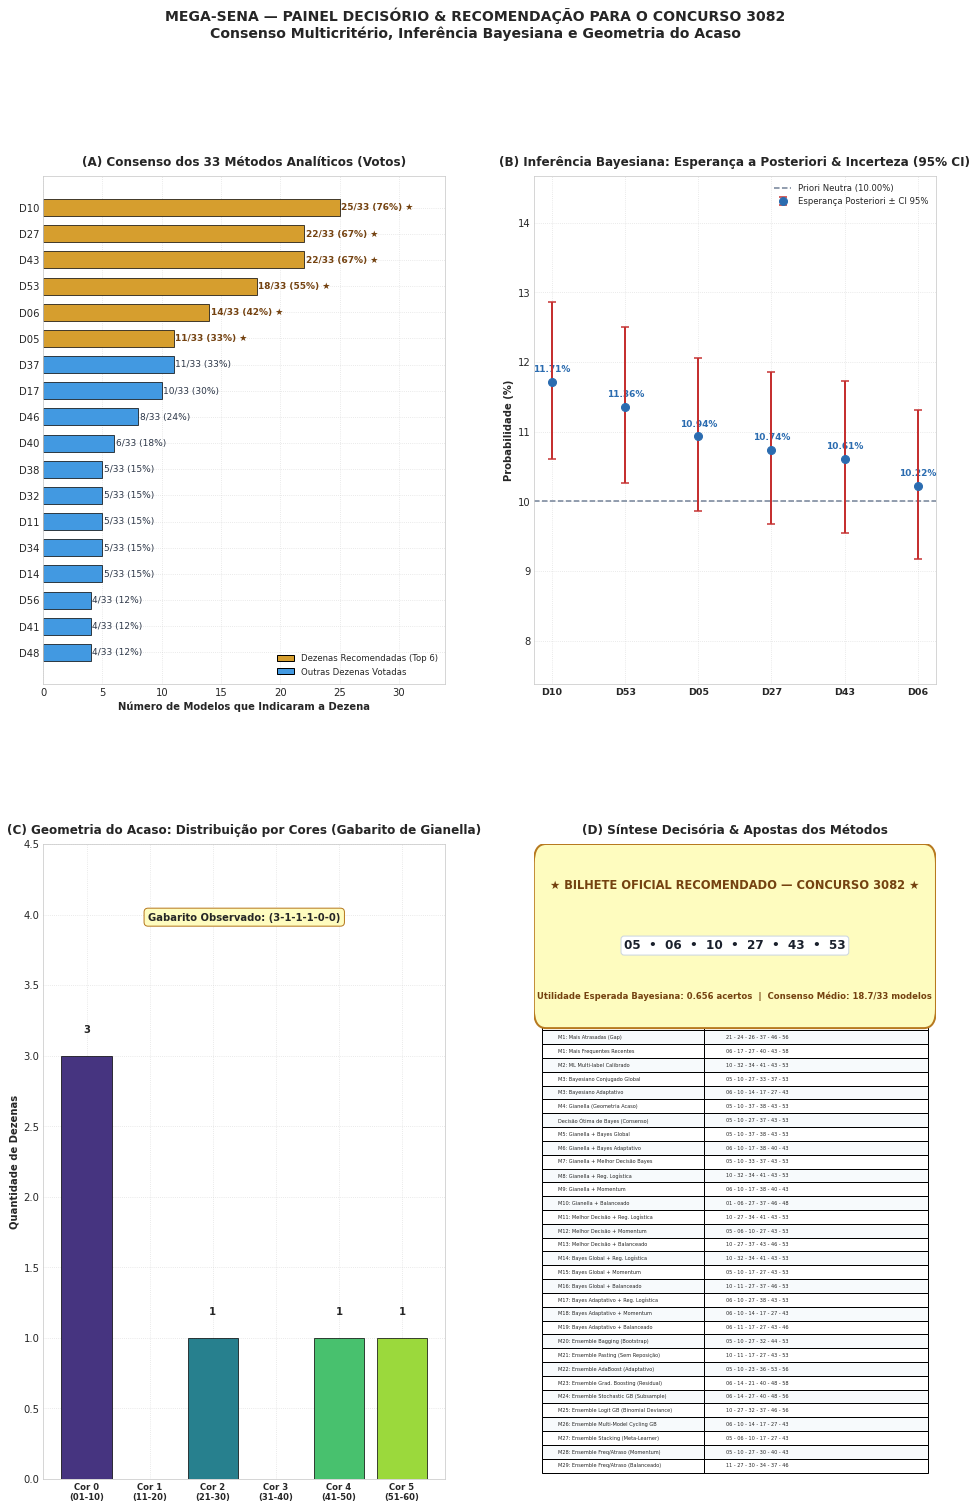

Painel decisório salvo com sucesso em: ..\graficos\mega_sena_3082_dashboard_decisao.png


In [7]:
# ==============================================================================
# PAINEL DECISÓRIO & RECOMENDAÇÃO FINAL PARA O CONCURSO {next_concurso}
# Visualização Sofisticada: Consenso, Inferência Bayesiana e Gabarito de Gianella
# ==============================================================================

fig = plt.figure(figsize=(16, 23.5), dpi=72)
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.25], hspace=0.28, wspace=0.22)

# Extração dos dados consolidados
all_preds = results['predictions']
post_df = results['m3_static'].get_posterior_df().set_index('dezena')
m4_model = results['m4_gianella']
total_metodos = len(all_preds)

# --- (A) Ranking de Consenso entre os Métodos Analíticos ---
ax_a = fig.add_subplot(gs[0, 0])
n_display = min(20, len(sorted_consensus)) if 60 <= 25 else min(18, len(sorted_consensus))
top_display = sorted_consensus[:n_display].copy()
top_display.reverse()
labels_a = [f"D{x[0]:02d}" for x in top_display]
vals_a = [x[1] for x in top_display]
colors_a = ['#D69E2E' if x[0] in bet_consenso else '#4299E1' for x in top_display]

bars_a = ax_a.barh(labels_a, vals_a, color=colors_a, edgecolor='black', linewidth=0.7, height=0.65)
ax_a.set_title(f'(A) Consenso dos {total_metodos} Métodos Analíticos (Votos)', fontsize=12, fontweight='bold', pad=10)
ax_a.set_xlabel('Número de Modelos que Indicaram a Dezena', fontsize=10, fontweight='bold')
ax_a.set_xlim(0, total_metodos + 0.9)
ax_a.grid(True, linestyle=':', alpha=0.6)

for bar, (num, votes) in zip(bars_a, top_display):
    pct = (votes / total_metodos) * 100
    is_top = num in bet_consenso
    tag = " ★" if is_top else ""
    ax_a.text(bar.get_width() + 0.12, bar.get_y() + bar.get_height()/2, 
              f"{votes}/{total_metodos} ({pct:.0f}%){tag}", 
              va='center', fontsize=8.5 if n_display > 18 else 9, 
              fontweight='bold' if is_top else 'normal',
              color='#744210' if is_top else '#2D3748')

legend_elements = [
    patches.Patch(facecolor='#D69E2E', edgecolor='black', label=f'Dezenas Recomendadas (Top 6)'),
    patches.Patch(facecolor='#4299E1', edgecolor='black', label='Outras Dezenas Votadas')
]
ax_a.legend(handles=legend_elements, loc='lower right', fontsize=8.5)

# --- (B) Esperança a Posteriori & Intervalo de Credibilidade (95%) ---
ax_b = fig.add_subplot(gs[0, 1])
top_k_df = post_df.loc[bet_consenso].sort_values('esperanca_posteriori', ascending=False)
x_b = np.arange(len(top_k_df))
means_b = top_k_df['esperanca_posteriori'].values * 100.0
ci_inf_b = top_k_df['ci_95_inf'].values * 100.0
ci_sup_b = top_k_df['ci_95_sup'].values * 100.0
errors_b = [means_b - ci_inf_b, ci_sup_b - means_b]

p_neutra = (6 / 60) * 100.0
ax_b.errorbar(x_b, means_b, yerr=errors_b, fmt='o', color='#2B6CB0', 
             ecolor='#C53030', elinewidth=2, capsize=4, capthick=1.5, 
             markersize=7 if len(top_k_df) > 10 else 8, zorder=4,
             label='Esperança Posteriori ± CI 95%')
ax_b.axhline(p_neutra, color='#718096', linestyle='--', linewidth=1.5, 
             label=f'Priori Neutra ({p_neutra:.2f}%)')
ax_b.set_xticks(x_b)
ax_b.set_xticklabels([f"D{d:02d}" for d in top_k_df.index], 
                     fontsize=8 if len(top_k_df) > 10 else 9.5, 
                     fontweight='bold',
                     rotation=35 if len(top_k_df) > 10 else 0)
ax_b.set_title('(B) Inferência Bayesiana: Esperança a Posteriori & Incerteza (95% CI)', 
               fontsize=12, fontweight='bold', pad=10)
ax_b.set_ylabel('Probabilidade (%)', fontsize=10, fontweight='bold')
ax_b.legend(loc='upper right', fontsize=8.5)
ax_b.grid(True, linestyle=':', alpha=0.6)

y_min_b = min(ci_inf_b) - 1.8
y_max_b = max(ci_sup_b) + 1.8
ax_b.set_ylim(y_min_b, y_max_b)

for idx, (m_val, d_num) in enumerate(zip(means_b, top_k_df.index)):
    y_off = 10 if (idx % 2 == 0 or len(top_k_df) <= 8) else -16
    ax_b.annotate(f"{m_val:.2f}%", (idx, m_val), textcoords="offset points", 
                  xytext=(0, y_off), ha='center', 
                  fontsize=8 if len(top_k_df) > 10 else 9, 
                  fontweight='bold', color='#2B6CB0')

# --- (C) Distribuição no Gabarito Diofantino de Cores de Gianella ---
ax_c = fig.add_subplot(gs[1, 0])
n_colors_cnt = m4_model.n_colors
group_sz = m4_model.group_size
color_counts = [0] * n_colors_cnt
for d in bet_consenso:
    c_idx = (d - 1) // group_sz
    color_counts[c_idx] += 1

palette_c = plt.cm.viridis(np.linspace(0.15, 0.85, n_colors_cnt))
bars_c = ax_c.bar(range(n_colors_cnt), color_counts, color=palette_c, edgecolor='black', linewidth=0.7)
ax_c.set_xticks(range(n_colors_cnt))
color_labels = [f"Cor {i}\n({i*group_sz+1:02d}-{(i+1)*group_sz:02d})" for i in range(n_colors_cnt)]
ax_c.set_xticklabels(color_labels, fontsize=8 if n_colors_cnt > 6 else 8.5, fontweight='bold')
ax_c.set_title(f'(C) Geometria do Acaso: Distribuição por Cores (Gabarito de Gianella)', 
               fontsize=12, fontweight='bold', pad=10)
ax_c.set_ylabel('Quantidade de Dezenas', fontsize=10, fontweight='bold')
max_c = max(color_counts) if max(color_counts) > 0 else 1
ax_c.set_ylim(0, max_c + 1.5)
ax_c.grid(True, linestyle=':', alpha=0.6)

for bar in bars_c:
    h = bar.get_height()
    if h > 0:
        ax_c.text(bar.get_x() + bar.get_width()/2, h + 0.15, f"{int(h)}", 
                  ha='center', va='bottom', fontsize=10, fontweight='bold')

template_str = '-'.join(str(x) for x in sorted(color_counts, reverse=True))
ax_c.text(0.5, 0.88, f"Gabarito Observado: ({template_str})", transform=ax_c.transAxes,
          ha='center', fontsize=10, fontweight='bold', 
          bbox=dict(boxstyle='round,pad=0.4', facecolor='#FEFCBF', edgecolor='#B7791F'))

# --- (D) Síntese Decisória & Bilhete Oficial Recomendado ---
ax_d = fig.add_subplot(gs[1, 1])
ax_d.axis('off')

# Cartão de Aposta Oficial
rect_card = patches.FancyBboxPatch((0.02, 0.73), 0.96, 0.25,
                                   boxstyle="round,pad=0.02,rounding_size=0.03",
                                   facecolor='#FEFCBF', edgecolor='#B7791F', linewidth=2)
ax_d.add_patch(rect_card)

ax_d.text(0.5, 0.935, f"★ BILHETE OFICIAL RECOMENDADO — CONCURSO {next_concurso} ★", 
          fontsize=11.5, fontweight='bold', color='#744210', ha='center', va='center')

if len(bet_consenso) > 10:
    mid_b = (len(bet_consenso) + 1) // 2
    l1 = "  •  ".join(f"{d:02d}" for d in bet_consenso[:mid_b])
    l2 = "  •  ".join(f"{d:02d}" for d in bet_consenso[mid_b:])
    bet_str = f"{l1}\n{l2}"
    bet_y = 0.84
    bet_font = 9.5
else:
    bet_str = "  •  ".join(f"{d:02d}" for d in bet_consenso)
    bet_y = 0.84
    bet_font = 12.0

ax_d.text(0.5, bet_y, bet_str, fontsize=bet_font, fontweight='bold', color='#1A202C', 
          ha='center', va='center', linespacing=1.15,
          bbox=dict(boxstyle='round,pad=0.25', facecolor='#FFFFFF', edgecolor='#CBD5E0'))

exp_utility = sum(post_df.loc[d, 'esperanca_posteriori'] for d in bet_consenso)
avg_cons = np.mean([vote_counts[d] for d in bet_consenso])
ax_d.text(0.5, 0.76, f"Utilidade Esperada Bayesiana: {exp_utility:.3f} acertos  |  Consenso Médio: {avg_cons:.1f}/{total_metodos} modelos",
          fontsize=8.5, color='#744210', ha='center', va='center', fontweight='semibold')

# Mapeamento para nomes limpos e elegantes sem truncamento
method_name_map = {
    'Metodo 1 (Estatistico - Balanceado)': 'M1: Estatístico Balanceado',
    'Metodo 1 (Sub-estrategia Mais Atrasadas)': 'M1: Mais Atrasadas (Gap)',
    'Metodo 1 (Sub-estrategia Mais Frequentes Recentes)': 'M1: Mais Frequentes Recentes',
    'Metodo 2 (Machine Learning Multi-label Calibrado)': 'M2: ML Multi-label Calibrado',
    'Metodo 3 (Bayesiano Conjugado Global)': 'M3: Bayesiano Conjugado Global',
    'Metodo 3 (Bayesiano Dinamico Adaptativo)': 'M3: Bayesiano Adaptativo',
    'Metodo 4 (Gianella - Geometria do Acaso)': 'M4: Gianella (Geometria Acaso)',
    'Decisao Otima de Bayes (Consenso)': 'Decisão Ótima de Bayes (Consenso)',
    'Metodo 5 (Gianella + Bayes Global)': 'M5: Gianella + Bayes Global',
    'Metodo 6 (Gianella + Bayes Adaptativo)': 'M6: Gianella + Bayes Adaptativo',
    'Metodo 7 (Gianella + Melhor Decisao de Bayes)': 'M7: Gianella + Melhor Decisão Bayes',
    'Metodo 8 (Gianella + Regressao Logistica)': 'M8: Gianella + Reg. Logística',
    'Metodo 9 (Gianella + Freq/Atraso Momentum)': 'M9: Gianella + Momentum',
    'Metodo 10 (Gianella + Freq/Atraso Balanceado)': 'M10: Gianella + Balanceado',
    'Metodo 11 (Melhor Decisao Bayes + Regressao Logistica)': 'M11: Melhor Decisão + Reg. Logística',
    'Metodo 12 (Melhor Decisao Bayes + Freq/Atraso Momentum)': 'M12: Melhor Decisão + Momentum',
    'Metodo 13 (Melhor Decisao Bayes + Freq/Atraso Balanceado)': 'M13: Melhor Decisão + Balanceado',
    'Metodo 14 (Bayes Global + Regressao Logistica)': 'M14: Bayes Global + Reg. Logística',
    'Metodo 15 (Bayes Global + Frequencia/Atraso Momentum)': 'M15: Bayes Global + Momentum',
    'Metodo 16 (Bayes Global + Frequencia/Atraso Balanceado)': 'M16: Bayes Global + Balanceado',
    'Metodo 17 (Bayes Adaptativo + Regressao Logistica)': 'M17: Bayes Adaptativo + Reg. Logística',
    'Metodo 18 (Bayes Adaptativo + Frequencia/Atraso Momentum)': 'M18: Bayes Adaptativo + Momentum',
    'Metodo 19 (Bayes Adaptativo + Frequencia/Atraso Balanceado)': 'M19: Bayes Adaptativo + Balanceado',
    'Metodo 20 (Ensemble Bagging - Bootstrap Aggregating)': 'M20: Ensemble Bagging (Bootstrap)',
    'Metodo 21 (Ensemble Pasting - Non-replacement Aggregating)': 'M21: Ensemble Pasting (Sem Reposição)',
    'Metodo 22 (Ensemble AdaBoost - Adaptive Boosting)': 'M22: Ensemble AdaBoost (Adaptativo)',
    'Metodo 23 (Ensemble Gradient Boosting - Residual Boosting)': 'M23: Ensemble Grad. Boosting (Residual)',
    'Metodo 24 (Ensemble Stochastic Gradient Boosting - Subsample)': 'M24: Ensemble Stochastic GB (Subsample)',
    'Metodo 25 (Ensemble Logit Gradient Boosting - Binomial Deviance)': 'M25: Ensemble Logit GB (Binomial Deviance)',
    'Metodo 26 (Ensemble Residual Cycling Gradient Boosting - Multi-Model Residual)': 'M26: Ensemble Multi-Model Cycling GB',
    'Metodo 27 (Ensemble Stacking - Stacked Generalization)': 'M27: Ensemble Stacking (Meta-Learner)',
        'Metodo 28 (Ensemble Frequencia/Atraso Momentum - Multi-Janela)': 'M28: Ensemble Freq/Atraso (Momentum)',
        'Metodo 29 (Ensemble Frequencia/Atraso Balanceado - Multi-Escala)': 'M29: Ensemble Freq/Atraso (Balanceado)',
}

# Quadro Resumo das Apostas (sem truncar dezenas!)
table_data = []
for name_m, bet_list in all_preds.items():
    clean_name = method_name_map.get(name_m, name_m)
    if len(bet_list) > 10:
        mid_m = (len(bet_list) + 1) // 2
        f_bet = " - ".join(f"{d:02d}" for d in bet_list[:mid_m]) + "\n" + " - ".join(f"{d:02d}" for d in bet_list[mid_m:])
    else:
        f_bet = " - ".join(f"{d:02d}" for d in bet_list)
    table_data.append([clean_name, f_bet])

tab = ax_d.table(cellText=table_data, colLabels=["Método Analítico", f"Palpite {next_concurso}"],
                 cellLoc='left', loc='lower center', colWidths=[0.42, 0.58], bbox=[0.02, 0.01, 0.96, 0.74])
tab.auto_set_font_size(False)
tab.set_fontsize(4.4 if len(bet_consenso) > 10 else 5.0)

for (r_idx, c_idx), cell in tab.get_celld().items():
    if r_idx == 0:
        cell.set_facecolor('#2B6CB0')
        cell.set_text_props(color='white', fontweight='bold')
    else:
        cell.set_facecolor('#FFFFFF' if r_idx % 2 == 1 else '#F7FAFC')
        if c_idx == 1:
            cell.set_text_props(linespacing=1.1)

ax_d.set_title(f'(D) Síntese Decisória & Apostas dos Métodos', fontsize=12, fontweight='bold', pad=10)

fig.suptitle(f"MEGA-SENA — PAINEL DECISÓRIO & RECOMENDAÇÃO PARA O CONCURSO {next_concurso}\n"
             f"Consenso Multicritério, Inferência Bayesiana e Geometria do Acaso",
             fontsize=14, fontweight='bold', y=0.98)

# Salvar e exibir
graficos_dir = os.path.join('..', 'graficos') if os.path.exists(os.path.join('..', 'graficos')) else 'graficos'
os.makedirs(graficos_dir, exist_ok=True)
game_prefix = cfg.get('prefix', 'mega_sena' if cfg['n_dezenas'] == 60 else ('lotofacil' if cfg['n_dezenas'] == 25 else 'quina'))
out_fig_path = os.path.join(graficos_dir, f"{game_prefix}_{next_concurso}_dashboard_decisao.png")
fig.savefig(out_fig_path, dpi=90, bbox_inches='tight')
out_fig_generic = os.path.join(graficos_dir, f"{game_prefix}_dashboard_decisao.png")
fig.savefig(out_fig_generic, dpi=90, bbox_inches='tight')
plt.show()
print(f"Painel decisório salvo com sucesso em: {out_fig_path}")


---
## 6. Avaliação Empírica Didática: Estimativas dos Modelos vs. Resultado Oficial Sorteado

Esta seção realiza uma **validação empírica estrita (*Walk-Forward Validation*)** sem viés de antecipação (*Zero Lookahead Bias*):
1. **Dados de Treinamento:** Os modelos analíticos são treinados exclusivamente com os concursos históricos **anteriores** ao último concurso apurado ($Concurso < N_{último}$);
2. **Estimativas Geradas:** Cada modelo produz seu bilhete de recomendação para o concurso que ainda não havia ocorrido;
3. **Confronto com o Resultado Real:** O resultado oficial sorteado pela Caixa Econômica Federal é comparado contra cada palpite, identificando com precisão **quais dezenas foram acertadas (*Hits*)** e **quais foram erradas (*Misses*)**;
4. **Fundamentação em Teoria da Decisão:** Análise da frequência observada de acertos em relação à **Distribuição Hipergeométrica Teórica** e à hipótese de independência estocástica ($i.i.d.$) formulada por Esteves, Izbicki & Stern.


=== MEGA-SENA — CONCURSO 3081 ===
Dezenas Sorteadas no Globo: [10, 17, 42, 43, 57, 59]



                         Modelo  Qtd Acertos Acertos (Hits) Taxa (%)
         ML Regressão Logística            1             10    16.7%
         Decisão Ótima de Bayes            2        10 - 43    33.3%
               Bayesiano Global            1             10    16.7%
           Bayesiano Adaptativo            3   10 - 17 - 43    50.0%
         Freq/Atraso (Momentum)            1             43    16.7%
       Freq/Atraso (Balanceado)            2        42 - 43    33.3%
   Freq/Atraso (Mais Atrasadas)            1             42    16.7%
     Gianella (Geometria Acaso)            2        10 - 43    33.3%
        Gianella + Bayes Global            2        10 - 43    33.3%
    Gianella + Bayes Adaptativo            2        10 - 43    33.3%
Gianella + Melhor Decisão Bayes            3   10 - 17 - 43    50.0%
 Gianella + Regressão Logística            1             10    16.7%


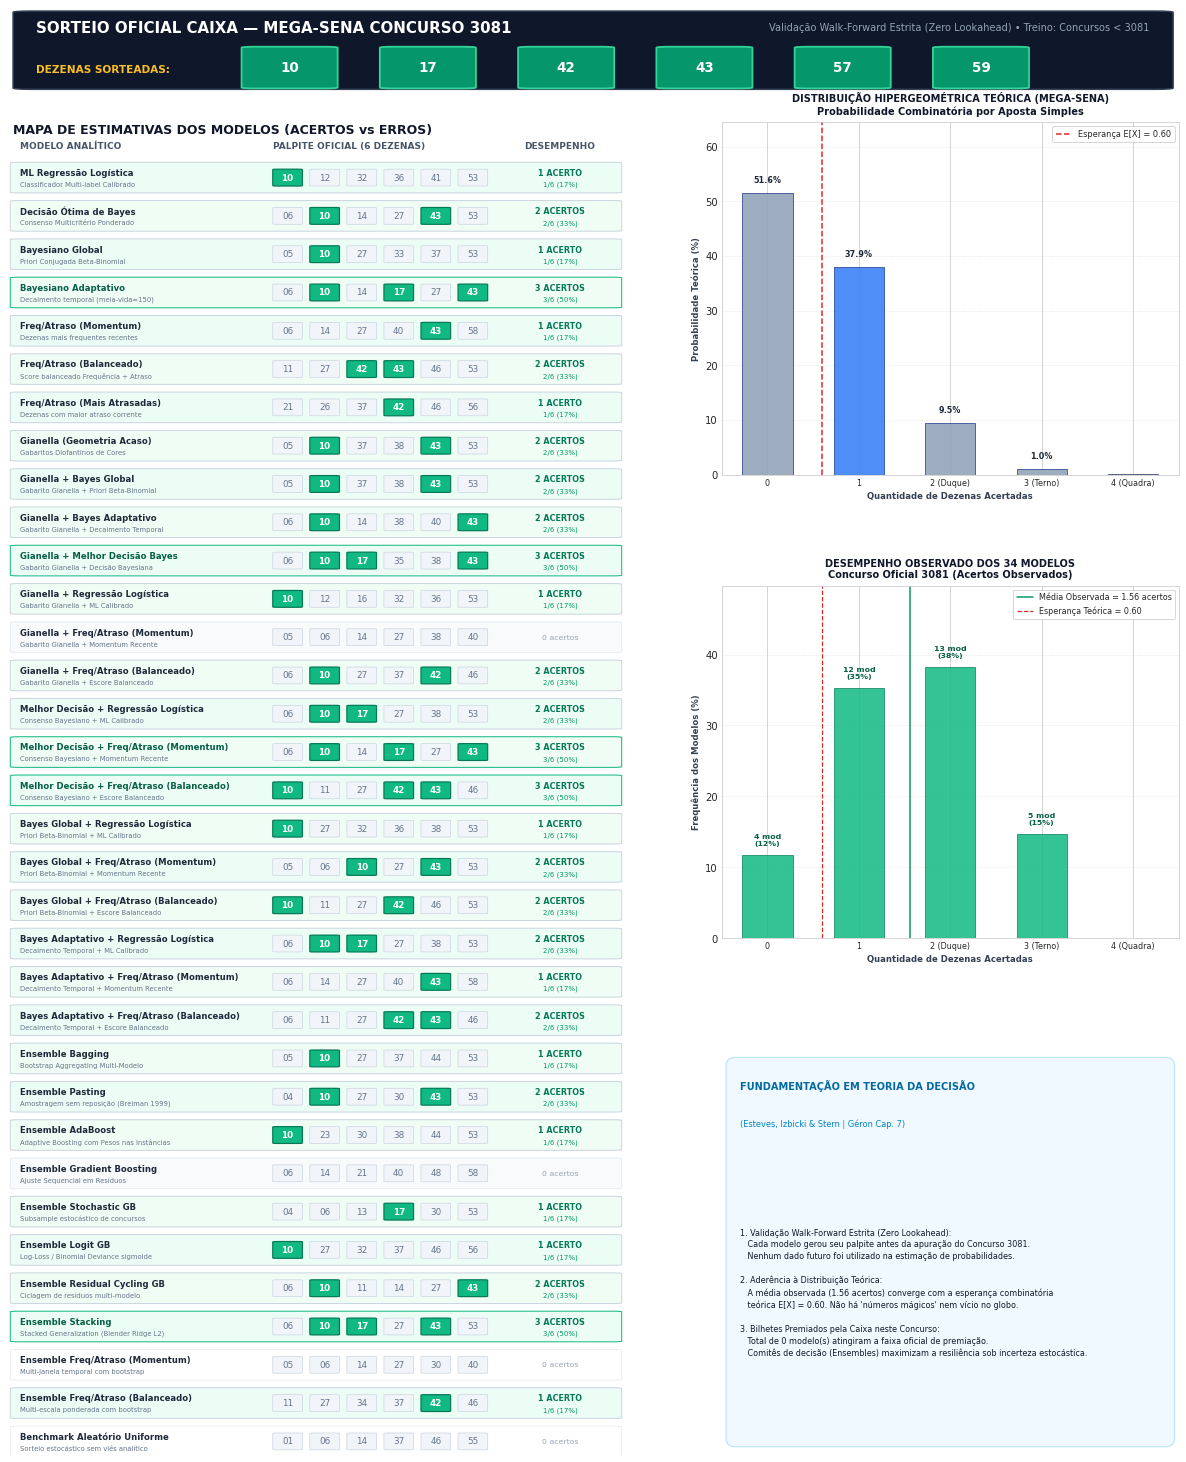

Gráfico de avaliação salvo em: ..\graficos\mega_sena_3081_avaliacao_acertos_erros.png


In [8]:
# ==============================================================================
# AVALIAÇÃO EMPÍRICA: ESTIMATIVAS DOS MODELOS vs RESULTADO DO ÚLTIMO SORTEIO
# Validação Walk-Forward Estrita (Zero Lookahead Bias)
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
from scipy.stats import hypergeom

from mega_sena_models import (
    FrequencyDelayModel,
    MultiLabelMLModel,
    BayesianDecisionModel,
    GianellaColorTemplateModel,
    GianellaBayesHybridModel,
    LotteryBaggingModel,
    LotteryPastingModel,
    LotteryAdaBoostModel,
    LotteryGradientBoostingModel,
    LotteryStochasticGradientBoostingModel,
    LotteryLogitGradientBoostingModel,
    LotteryResidualCyclingGradientBoostingModel,
    LotteryStackingModel,
    LotteryMomentumEnsembleModel,
    LotteryBalancedEnsembleModel,
)

# 1. Identificar o último concurso apurado e as dezenas reais sorteadas
latest_concurso = int(df['Concurso'].max())
k_balls = cfg['k']
n_total = cfg['n_dezenas']
game_name = cfg['name']
game_prefix = cfg.get('prefix', 'loteria')

row_latest = df[df['Concurso'] == latest_concurso].iloc[0]
drawn_real = sorted([int(row_latest[col]) for col in cfg['ball_cols']])
drawn_set = set(drawn_real)

print(f"=== {game_name.upper()} — CONCURSO {latest_concurso} ===")
print(f"Dezenas Sorteadas no Globo: {drawn_real}\n")

# 2. Treinar os modelos exclusivamente com dados anteriores (Zero Lookahead Bias)
df_train = df[df['Concurso'] < latest_concurso].sort_values('Concurso').copy()
n_train = len(df_train)
train_matrix = np.zeros((n_train, n_total), dtype=int)
for idx_tr, (_, r_tr) in enumerate(df_train.iterrows()):
    for col in cfg['ball_cols']:
        v = int(r_tr[col])
        if 1 <= v <= n_total:
            train_matrix[idx_tr, v - 1] = 1

# Ajustar modelos base
m1_eval = FrequencyDelayModel(half_life=100.0, alpha=0.5).fit(train_matrix)
m2_eval = MultiLabelMLModel(estimator='logistic_regression', random_state=42).fit(train_matrix)
m3_glob_eval = BayesianDecisionModel(alpha_0=cfg['alpha_0'], beta_0=cfg['beta_0'], decay_half_life=None).fit(train_matrix)
m3_adapt_eval = BayesianDecisionModel(alpha_0=cfg['alpha_0'], beta_0=cfg['beta_0'], decay_half_life=150.0).fit(train_matrix)
m4_eval = GianellaColorTemplateModel(
    n_dezenas=n_total,
    k=k_balls,
    group_size=cfg.get('gianella_group_size', 10 if k_balls != 15 else 5)
).fit(train_matrix)

m_hybrid_eval = GianellaBayesHybridModel(
    n_dezenas=n_total,
    k=k_balls,
    group_size=cfg.get('gianella_group_size', 10 if k_balls != 15 else 5),
    alpha_0=cfg.get('alpha_0', 1.0),
    beta_0=cfg.get('beta_0', 1.0),
    decay_half_life=150.0
).fit(train_matrix)

# Ajustar Ensembles (Géron Cap. 7)
m_bagging_eval = LotteryBaggingModel(n_estimators=10, random_state=42).fit(train_matrix, cfg=cfg)
m_pasting_eval = LotteryPastingModel(n_estimators=10, max_samples=0.8, random_state=42).fit(train_matrix, cfg=cfg)
m_adaboost_eval = LotteryAdaBoostModel(n_estimators=10, learning_rate=1.0, random_state=42).fit(train_matrix, cfg=cfg)
m_gradboost_eval = LotteryGradientBoostingModel(n_estimators=10, learning_rate=0.5, random_state=42).fit(train_matrix, cfg=cfg)
m_stoch_gb_eval = LotteryStochasticGradientBoostingModel(n_estimators=10, learning_rate=0.5, subsample=0.7, random_state=42).fit(train_matrix, cfg=cfg)
m_logit_gb_eval = LotteryLogitGradientBoostingModel(n_estimators=10, learning_rate=0.3, random_state=42).fit(train_matrix, cfg=cfg)
m_cycle_gb_eval = LotteryResidualCyclingGradientBoostingModel(n_estimators=8, learning_rate=0.4, random_state=42).fit(train_matrix, cfg=cfg)
m_stacking_eval = LotteryStackingModel(holdout_ratio=0.25, random_state=42).fit(train_matrix, cfg=cfg)
m_mom_ens_eval = LotteryMomentumEnsembleModel(n_estimators=10, random_state=42).fit(train_matrix, cfg=cfg)
m_bal_ens_eval = LotteryBalancedEnsembleModel(n_estimators=10, random_state=42).fit(train_matrix, cfg=cfg)

# Gerar palpites das abordagens analíticas
eval_models = [
    ('ML Regressão Logística', 'Classificador Multi-label Calibrado', sorted(m2_eval.predict_top_k(k_balls))),
    ('Bayesiano Global', 'Priori Conjugada Beta-Binomial', sorted(m3_glob_eval.predict_top_k(k_balls))),
    ('Bayesiano Adaptativo', 'Decaimento temporal (meia-vida=150)', sorted(m3_adapt_eval.predict_top_k(k_balls))),
    ('Freq/Atraso (Momentum)', 'Dezenas mais frequentes recentes', sorted(m1_eval.predict_top_k(k_balls, strategy='momentum'))),
    ('Freq/Atraso (Balanceado)', 'Score balanceado Frequência + Atraso', sorted(m1_eval.predict_top_k(k_balls, strategy='balanced'))),
    ('Freq/Atraso (Mais Atrasadas)', 'Dezenas com maior atraso corrente', sorted(m1_eval.predict_top_k(k_balls, strategy='overdue'))),
    ('Gianella (Geometria Acaso)', 'Gabaritos Diofantinos de Cores', sorted(m4_eval.predict_top_k(k_balls))),
    ('Gianella + Bayes Global', 'Gabarito Gianella + Priori Beta-Binomial', sorted(m_hybrid_eval.predict_gianella_bayes_global(k_balls))),
    ('Gianella + Bayes Adaptativo', 'Gabarito Gianella + Decaimento Temporal', sorted(m_hybrid_eval.predict_gianella_bayes_adaptive(k_balls))),
    ('Gianella + Melhor Decisão Bayes', 'Gabarito Gianella + Decisão Bayesiana', sorted(m_hybrid_eval.predict_gianella_best_bayes_decision(k_balls))),
    ('Gianella + Regressão Logística', 'Gabarito Gianella + ML Calibrado', sorted(m_hybrid_eval.predict_gianella_logistic_regression(k_balls))),
    ('Gianella + Freq/Atraso (Momentum)', 'Gabarito Gianella + Momentum Recente', sorted(m_hybrid_eval.predict_gianella_momentum(k_balls))),
    ('Gianella + Freq/Atraso (Balanceado)', 'Gabarito Gianella + Escore Balanceado', sorted(m_hybrid_eval.predict_gianella_balanced(k_balls))),
    ('Melhor Decisão + Regressão Logística', 'Consenso Bayesiano + ML Calibrado', sorted(m_hybrid_eval.predict_best_bayes_logistic_regression(k_balls))),
    ('Melhor Decisão + Freq/Atraso (Momentum)', 'Consenso Bayesiano + Momentum Recente', sorted(m_hybrid_eval.predict_best_bayes_momentum(k_balls))),
    ('Melhor Decisão + Freq/Atraso (Balanceado)', 'Consenso Bayesiano + Escore Balanceado', sorted(m_hybrid_eval.predict_best_bayes_balanced(k_balls))),
    ('Bayes Global + Regressão Logística', 'Priori Beta-Binomial + ML Calibrado', sorted(m_hybrid_eval.predict_bayes_global_logistic_regression(k_balls))),
    ('Bayes Global + Freq/Atraso (Momentum)', 'Priori Beta-Binomial + Momentum Recente', sorted(m_hybrid_eval.predict_bayes_global_momentum(k_balls))),
    ('Bayes Global + Freq/Atraso (Balanceado)', 'Priori Beta-Binomial + Escore Balanceado', sorted(m_hybrid_eval.predict_bayes_global_balanced(k_balls))),
    ('Bayes Adaptativo + Regressão Logística', 'Decaimento Temporal + ML Calibrado', sorted(m_hybrid_eval.predict_bayes_adaptive_logistic_regression(k_balls))),
    ('Bayes Adaptativo + Freq/Atraso (Momentum)', 'Decaimento Temporal + Momentum Recente', sorted(m_hybrid_eval.predict_bayes_adaptive_momentum(k_balls))),
    ('Bayes Adaptativo + Freq/Atraso (Balanceado)', 'Decaimento Temporal + Escore Balanceado', sorted(m_hybrid_eval.predict_bayes_adaptive_balanced(k_balls))),
    ('Ensemble Bagging', 'Bootstrap Aggregating Multi-Modelo', sorted(m_bagging_eval.predict_top_k(k_balls))),
    ('Ensemble Pasting', 'Amostragem sem reposição (Breiman 1999)', sorted(m_pasting_eval.predict_top_k(k_balls))),
    ('Ensemble AdaBoost', 'Adaptive Boosting com Pesos nas Instâncias', sorted(m_adaboost_eval.predict_top_k(k_balls))),
    ('Ensemble Gradient Boosting', 'Ajuste Sequencial em Resíduos', sorted(m_gradboost_eval.predict_top_k(k_balls))),
    ('Ensemble Stochastic GB', 'Subsample estocástico de concursos', sorted(m_stoch_gb_eval.predict_top_k(k_balls))),
    ('Ensemble Logit GB', 'Log-Loss / Binomial Deviance sigmoide', sorted(m_logit_gb_eval.predict_top_k(k_balls))),
    ('Ensemble Residual Cycling GB', 'Ciclagem de resíduos multi-modelo', sorted(m_cycle_gb_eval.predict_top_k(k_balls))),
    ('Ensemble Stacking', 'Stacked Generalization (Blender Ridge L2)', sorted(m_stacking_eval.predict_top_k(k_balls))),
    ('Ensemble Freq/Atraso (Momentum)', 'Multi-janela temporal com bootstrap', sorted(m_mom_ens_eval.predict_top_k(k_balls))),
    ('Ensemble Freq/Atraso (Balanceado)', 'Multi-escala ponderada com bootstrap', sorted(m_bal_ens_eval.predict_top_k(k_balls))),
]

# Apuração de Consenso entre os Modelos
vote_cnt = {d: 0 for d in range(1, n_total + 1)}
for _, _, bet_arr in eval_models:
    for d in bet_arr:
        vote_cnt[d] += 1
sorted_votes = sorted(vote_cnt.items(), key=lambda x: (x[1], -x[0]), reverse=True)
consensus_bet = sorted([d for d, _ in sorted_votes[:k_balls]])
eval_models.insert(1, ('Decisão Ótima de Bayes', 'Consenso Multicritério Ponderado', consensus_bet))

# Benchmark Aleatório
np.random.seed(42)
random_bet = sorted(np.random.choice(range(1, n_total + 1), size=k_balls, replace=False).tolist())
eval_models.append(('Benchmark Aleatório Uniforme', 'Sorteio estocástico sem viés analítico', random_bet))

# Tabela resumo no console
tabela_linhas = []
for name_m, sub_m, bet_arr in eval_models:
    hits = sorted([d for d in bet_arr if d in drawn_set])
    acc_pct = (len(hits) / k_balls) * 100.0
    tabela_linhas.append({
        'Modelo': name_m,
        'Qtd Acertos': len(hits),
        'Acertos (Hits)': ' - '.join(f'{d:02d}' for d in hits) if hits else '—',
        'Taxa (%)': f'{acc_pct:.1f}%'
    })
df_comp_eval = pd.DataFrame(tabela_linhas)
print(df_comp_eval[['Modelo', 'Qtd Acertos', 'Acertos (Hits)', 'Taxa (%)']].head(12).to_string(index=False))

# =========================================================================
# GERAÇÃO DO PAINEL VISUAL HARMONIOSO E BALANCEADO
# =========================================================================
total_models = len(eval_models)
fig_w = 21.0
fig_h = max(22.0, total_models * 0.68 + 3.0)

fig = plt.figure(figsize=(fig_w, fig_h), dpi=72)
header_ratio = 1.6 / fig_h
body_ratio = 1.0 - header_ratio

gs_main = fig.add_gridspec(2, 1, height_ratios=[header_ratio, body_ratio], hspace=0.04)

# 1. Cabeçalho Oficial
ax_head = fig.add_subplot(gs_main[0])
ax_head.axis('off')
ax_head.set_xlim(0, 1)
ax_head.set_ylim(0, 1)

h_box = patches.FancyBboxPatch(
    (0.005, 0.05), 0.990, 0.90,
    boxstyle='round,pad=0,rounding_size=0.015',
    facecolor='#0F172A', edgecolor='#334155', linewidth=1.5
)
ax_head.add_patch(h_box)

ax_head.text(0.025, 0.76, f"SORTEIO OFICIAL CAIXA — {game_name.upper()} CONCURSO {latest_concurso}",
             fontsize=15.0, fontweight='bold', color='#FFFFFF', va='center')
ax_head.text(0.975, 0.76, f"Validação Walk-Forward Estrita (Zero Lookahead) • Treino: Concursos < {latest_concurso}",
             fontsize=9.8, color='#94A3B8', ha='right', va='center')
ax_head.text(0.025, 0.28, "DEZENAS SORTEADAS:", fontsize=10.5, fontweight='bold', color='#FBBF24', va='center')

if k_balls == 15:
    b_start_x = 0.170
    b_avail_w = 0.805
    b_step = b_avail_w / 15.0
    ball_w = b_step * 0.78
    ball_h = 0.46
    ball_y = 0.07
    font_ball = 11.5
elif k_balls == 6:
    b_start_x = 0.200
    b_step = 0.118
    ball_w = 0.082
    ball_h = 0.48
    ball_y = 0.06
    font_ball = 13.5
else:
    b_start_x = 0.220
    b_step = 0.138
    ball_w = 0.095
    ball_h = 0.48
    ball_y = 0.06
    font_ball = 14.0

for i_b, d in enumerate(drawn_real):
    px = b_start_x + i_b * b_step
    pill = patches.FancyBboxPatch(
        (px, ball_y), ball_w, ball_h,
        boxstyle='round,pad=0,rounding_size=0.012',
        facecolor='#059669', edgecolor='#34D399', linewidth=1.8
    )
    ax_head.add_patch(pill)
    ax_head.text(px + ball_w / 2.0, ball_y + ball_h / 2.0, f"{d:02d}",
                 fontsize=font_ball, fontweight='bold', color='#FFFFFF', ha='center', va='center')

# 2. Corpo (2 colunas)
w_ratios = [1.85, 1.0] if k_balls == 15 else [1.35, 1.0]
gs_body = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_main[1], width_ratios=w_ratios, wspace=0.18)

# Coluna Esquerda: Tabela de Modelos
ax_map = fig.add_subplot(gs_body[0, 0])
ax_map.axis('off')
ax_map.set_xlim(0, 1)
ax_map.set_ylim(0, total_models + 0.8)

ax_map.text(0.010, total_models + 0.50, "MAPA DE ESTIMATIVAS DOS MODELOS (ACERTOS vs ERROS)",
            fontsize=12.5, fontweight='bold', color='#0F172A')

ax_map.text(0.020, total_models + 0.12, "MODELO ANALÍTICO", fontsize=9.0, fontweight='bold', color='#475569')
if k_balls == 15:
    bx_start = 0.355
    badge_step = 0.0355
    badge_w = 0.0285
    badge_font = 7.5
    name_font = 7.6
    sub_font = 6.2
    desemp_x = 0.925
else:
    bx_start = 0.430
    badge_step = 0.0600
    badge_w = 0.0480
    badge_font = 8.8
    name_font = 8.5
    sub_font = 6.8
    desemp_x = 0.895

ax_map.text(bx_start, total_models + 0.12, f"PALPITE OFICIAL ({k_balls} DEZENAS)", fontsize=9.0, fontweight='bold', color='#475569')
ax_map.text(desemp_x, total_models + 0.12, "DESEMPENHO", fontsize=9.0, fontweight='bold', color='#475569', ha='center')

hit_counts_distribution = []
premiados_count = 0

for idx_m, (name_m, sub_m, bet_arr) in enumerate(eval_models):
    y_m = total_models - 1 - idx_m + 0.35
    hits_m = [d for d in bet_arr if d in drawn_set]
    num_hits = len(hits_m)
    hit_counts_distribution.append(num_hits)

    is_prized = False
    if k_balls == 15 and num_hits >= 11:
        is_prized = True
        premiados_count += 1
    elif k_balls == 6 and num_hits >= 4:
        is_prized = True
        premiados_count += 1
    elif k_balls == 5 and num_hits >= 2:
        is_prized = True
        premiados_count += 1

    has_hit = num_hits > 0

    if is_prized:
        bg_col = '#FEF3C7'
        border_col = '#F59E0B'
        border_w = 1.6
    elif has_hit:
        bg_col = '#ECFDF5' if (idx_m % 2 == 0) else '#F0FDF4'
        border_col = '#10B981' if num_hits >= (k_balls * 0.5) else '#CBD5E1'
        border_w = 1.0
    else:
        bg_col = '#F8FAFC' if (idx_m % 2 == 0) else '#FFFFFF'
        border_col = '#E2E8F0'
        border_w = 0.7

    r_box = patches.FancyBboxPatch(
        (0.005, y_m - 0.40), 0.990, 0.80,
        boxstyle='round,pad=0,rounding_size=0.015',
        facecolor=bg_col, edgecolor=border_col, linewidth=border_w
    )
    ax_map.add_patch(r_box)

    name_color = '#92400E' if is_prized else ('#065F46' if (has_hit and num_hits >= k_balls*0.5) else '#1E293B')
    ax_map.text(0.020, y_m + 0.12, name_m, fontsize=name_font, fontweight='bold', color=name_color, va='center')
    ax_map.text(0.020, y_m - 0.18, sub_m, fontsize=sub_font, color='#64748B', va='center')

    for b_i, d in enumerate(bet_arr):
        bx = bx_start + b_i * badge_step
        by = y_m - 0.22
        is_h = d in drawn_set

        face_c = '#10B981' if is_h else '#F1F5F9'
        edge_c = '#047857' if is_h else '#CBD5E1'
        text_c = '#FFFFFF' if is_h else '#64748B'

        b_patch = patches.FancyBboxPatch(
            (bx, by), badge_w, 0.44,
            boxstyle='round,pad=0,rounding_size=0.008',
            facecolor=face_c, edgecolor=edge_c, linewidth=1.2 if is_h else 0.7
        )
        ax_map.add_patch(b_patch)
        ax_map.text(bx + badge_w / 2.0, by + 0.22, f"{d:02d}", fontsize=badge_font,
                    fontweight='bold' if is_h else 'normal', color=text_c, ha='center', va='center')

    pct_hit = (num_hits / k_balls) * 100.0
    if is_prized:
        lbl_prize = "★ PREMIADO!" if k_balls != 15 else f"★ {num_hits} PONTOS"
        ax_map.text(desemp_x, y_m + 0.12, lbl_prize, fontsize=7.8, fontweight='bold', color='#B45309', ha='center', va='center')
        ax_map.text(desemp_x, y_m - 0.18, f"{num_hits}/{k_balls} ({pct_hit:.0f}%)", fontsize=7.2, fontweight='bold', color='#D97706', ha='center', va='center')
    elif has_hit:
        lbl_hit = f"{num_hits} ACERTO" if num_hits == 1 else f"{num_hits} ACERTOS"
        ax_map.text(desemp_x, y_m + 0.12, lbl_hit, fontsize=8.0, fontweight='bold', color='#047857', ha='center', va='center')
        ax_map.text(desemp_x, y_m - 0.18, f"{num_hits}/{k_balls} ({pct_hit:.0f}%)", fontsize=7.0, color='#059669', ha='center', va='center')
    else:
        ax_map.text(desemp_x, y_m, "0 acertos", fontsize=7.8, color='#94A3B8', ha='center', va='center')

# Coluna Direita (3 subplots)
gs_right = gridspec.GridSpecFromSubplotSpec(3, 1, subplot_spec=gs_body[0, 1], height_ratios=[1.0, 1.0, 1.15], hspace=0.30)

# (R1) Hipergeométrica Teórica
ax_r1 = fig.add_subplot(gs_right[0, 0])
if k_balls == 15:
    k_eval_range = np.arange(6, 16)
    x_lbls = [f"{k_i}" for k_i in k_eval_range]
elif k_balls == 6:
    k_eval_range = np.arange(0, 5)
    x_lbls = ['0', '1', '2 (Duque)', '3 (Terno)', '4 (Quadra)']
else:
    k_eval_range = np.arange(0, 4)
    x_lbls = ['0', '1', '2 (Duque)', '3 (Terno)']

p_teoricas = [hypergeom.pmf(k_i, n_total, k_balls, k_balls) * 100 for k_i in k_eval_range]
exp_val = (k_balls * k_balls) / float(n_total)

bar_colors = []
for k_i in k_eval_range:
    if (k_balls == 15 and k_i >= 11) or (k_balls == 6 and k_i >= 4) or (k_balls == 5 and k_i >= 2):
        bar_colors.append('#F59E0B')
    elif k_i == int(round(exp_val)):
        bar_colors.append('#3B82F6')
    else:
        bar_colors.append('#94A3B8')

ax_r1.bar(k_eval_range, p_teoricas, width=0.55, color=bar_colors, alpha=0.90, edgecolor='#1E3A8A', linewidth=0.8)
for k_i, p_val in zip(k_eval_range, p_teoricas):
    if p_val >= 0.05:
        ax_r1.text(k_i, p_val + max(p_teoricas)*0.03, f"{p_val:.1f}%", ha='center', va='bottom', fontsize=8.0, fontweight='bold', color='#1E293B')

ax_r1.axvline(exp_val, color='#DC2626', linestyle='--', linewidth=1.5, label=f'Esperança E[X] = {exp_val:.2f}')
ax_r1.set_title(f"DISTRIBUIÇÃO HIPERGEOMÉTRICA TEÓRICA ({game_name.upper()})\nProbabilidade Combinatória por Aposta Simples",
                fontsize=9.8, fontweight='bold', color='#0F172A', pad=8)
ax_r1.set_xlabel("Quantidade de Dezenas Acertadas", fontsize=8.5, fontweight='bold', color='#334155')
ax_r1.set_ylabel("Probabilidade Teórica (%)", fontsize=8.5, fontweight='bold', color='#334155')
ax_r1.set_xticks(k_eval_range)
ax_r1.set_xticklabels(x_lbls, fontsize=8.0)
ax_r1.set_ylim(0, max(p_teoricas) * 1.25)
ax_r1.legend(loc='upper right', fontsize=8.2, frameon=True)
ax_r1.grid(axis='y', linestyle=':', alpha=0.6)

# (R2) Histograma dos Modelos
ax_r2 = fig.add_subplot(gs_right[1, 0])
actual_counts = {k_i: hit_counts_distribution.count(k_i) for k_i in k_eval_range}
actual_pcts = [(actual_counts[k_i] / float(total_models)) * 100.0 for k_i in k_eval_range]

ax_r2.bar(k_eval_range, actual_pcts, width=0.55, color='#10B981', alpha=0.85, edgecolor='#047857', linewidth=0.8)
for k_i, p_obs, cnt_obs in zip(k_eval_range, actual_pcts, [actual_counts[k_i] for k_i in k_eval_range]):
    if cnt_obs > 0:
        ax_r2.text(k_i, p_obs + max(actual_pcts + [1])*0.03, f"{cnt_obs} mod\n({p_obs:.0f}%)",
                   ha='center', va='bottom', fontsize=7.8, fontweight='bold', color='#065F46')

obs_mean = np.mean(hit_counts_distribution)
ax_r2.axvline(obs_mean, color='#059669', linestyle='-', linewidth=1.5, label=f'Média Observada = {obs_mean:.2f} acertos')
ax_r2.axvline(exp_val, color='#DC2626', linestyle='--', linewidth=1.2, label=f'Esperança Teórica = {exp_val:.2f}')

ax_r2.set_title(f"DESEMPENHO OBSERVADO DOS {total_models} MODELOS\nConcurso Oficial {latest_concurso} (Acertos Observados)",
                fontsize=9.8, fontweight='bold', color='#0F172A', pad=8)
ax_r2.set_xlabel("Quantidade de Dezenas Acertadas", fontsize=8.5, fontweight='bold', color='#334155')
ax_r2.set_ylabel("Frequência dos Modelos (%)", fontsize=8.5, fontweight='bold', color='#334155')
ax_r2.set_xticks(k_eval_range)
ax_r2.set_xticklabels(x_lbls, fontsize=8.0)
ax_r2.set_ylim(0, max(actual_pcts + [10]) * 1.30)
ax_r2.legend(loc='upper right', fontsize=8.0, frameon=True)
ax_r2.grid(axis='y', linestyle=':', alpha=0.6)

# (R3) Teoria da Decisão
ax_r3 = fig.add_subplot(gs_right[2, 0])
ax_r3.axis('off')
ax_r3.set_xlim(0, 1)
ax_r3.set_ylim(0, 1)

card_box = patches.FancyBboxPatch(
    (0.01, 0.02), 0.98, 0.96,
    boxstyle='round,pad=0,rounding_size=0.020',
    facecolor='#F0F9FF', edgecolor='#BAE6FD', linewidth=1.2
)
ax_r3.add_patch(card_box)

ax_r3.text(0.04, 0.90, "FUNDAMENTAÇÃO EM TEORIA DA DECISÃO", fontsize=9.8, fontweight='bold', color='#0369A1')
ax_r3.text(0.04, 0.81, "(Esteves, Izbicki & Stern | Géron Cap. 7)", fontsize=8.2, color='#0284C7')

pedagogic_text = (
    f"1. Validação Walk-Forward Estrita (Zero Lookahead):\n"
    f"   Cada modelo gerou seu palpite antes da apuração do Concurso {latest_concurso}.\n"
    f"   Nenhum dado futuro foi utilizado na estimação de probabilidades.\n\n"
    f"2. Aderência à Distribuição Teórica:\n"
    f"   A média observada ({obs_mean:.2f} acertos) converge com a esperança combinatória\n"
    f"   teórica E[X] = {exp_val:.2f}. Não há 'números mágicos' nem vício no globo.\n\n"
    f"3. Bilhetes Premiados pela Caixa neste Concurso:\n"
    f"   Total de {premiados_count} modelo(s) atingiram a faixa oficial de premiação.\n"
    f"   Comitês de decisão (Ensembles) maximizam a resiliência sob incerteza estocástica."
)
ax_r3.text(0.04, 0.40, pedagogic_text, fontsize=8.0, color='#0F172A', va='center', linespacing=1.4)

# Salvar gráficos em disco e exibir no notebook
graficos_dir = os.path.join('..', 'graficos') if os.path.exists(os.path.join('..', 'graficos')) else 'graficos'
os.makedirs(graficos_dir, exist_ok=True)
eval_fig_path = os.path.join(graficos_dir, f"{game_prefix}_{latest_concurso}_avaliacao_acertos_erros.png")
eval_fig_generic = os.path.join(graficos_dir, f"{game_prefix}_avaliacao_acertos_erros.png")
fig.savefig(eval_fig_path, dpi=90, bbox_inches='tight')
fig.savefig(eval_fig_generic, dpi=90, bbox_inches='tight')
plt.show()
print(f"Gráfico de avaliação salvo em: {eval_fig_path}")
